---
title: "Figures: The Diamond OLG Model"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=OLGModel.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/consumption/OLGModel/OLGModel.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/consumption/OLGModel/OLGModel.ipynb).

In [the Diamond OLG model](https://intertemporal-choice.github.io/content/consumption/olgmodel), the young work, consume and save, and the old live on their savings, which are the next period's capital. With Cobb-Douglas production, $\mathrm{f}(k) = k^{\varepsilon}$, and logarithmic utility, capital per young worker follows

$$
k_{t+1} = \mathcal{Q} k_{t}^{\varepsilon}, \qquad \mathcal{Q} = \frac{(1-\varepsilon)\beta}{\Xi(1+\beta)},
$$

where $\Xi$ is the growth factor of the population, and converges to the steady state $\bar{k} = \mathcal{Q}^{1/(1-\varepsilon)}$. Steady-state consumption per worker, $\mathrm{f}(\bar{k}) - \xi \bar{k}$ with $\xi = \Xi - 1$, is highest at the golden rule $k^{**} = (\xi/\varepsilon)^{1/(\varepsilon-1)}$, where $\mathrm{f}^{\prime}(k^{**}) = \xi$; an economy with more capital than that is dynamically inefficient. A period is a generation, here 30 years.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from intertemporal_choice import olg, style

style.use_book_style()

## The model

Each function is one of the chapter's equations; `k_next_payg` is the [Social Security chapter's](https://intertemporal-choice.github.io/content/consumption/socsecandkaccum) accumulation curve, with no population growth and the interest factor held fixed, as in its figure.

In [ ]:
def wage(k, epsilon):
    return (1 - epsilon) * k**epsilon


def interest_factor(k, epsilon):
    return 1 + epsilon * k ** (epsilon - 1)  # R = 1 + f'(k), with no depreciation


def Q(epsilon, beta, Xi):
    return (1 - epsilon) * beta / (Xi * (1 + beta))


def k_next(k, epsilon, beta, Xi):
    return Q(epsilon, beta, Xi) * k**epsilon


def k_bar(epsilon, beta, Xi):
    return Q(epsilon, beta, Xi) ** (1 / (1 - epsilon))


def k_golden(epsilon, xi):
    return (xi / epsilon) ** (1 / (epsilon - 1))  # where f'(k) = xi


def k_next_payg(k, epsilon, beta, z, R):
    """With contributions z from the young, paid to the old, and no population growth."""
    return Q(epsilon, beta, 1.0) * k**epsilon - z * (1 + R * beta) / (R * (1 + beta))

## The chapter's figures

A capital share of a third, a discount factor of 0.96 a year and population growth of 1 percent a year: capital per worker converging from a quarter of its steady state, and gross and net output per worker, with the golden rule $k^{**}$.

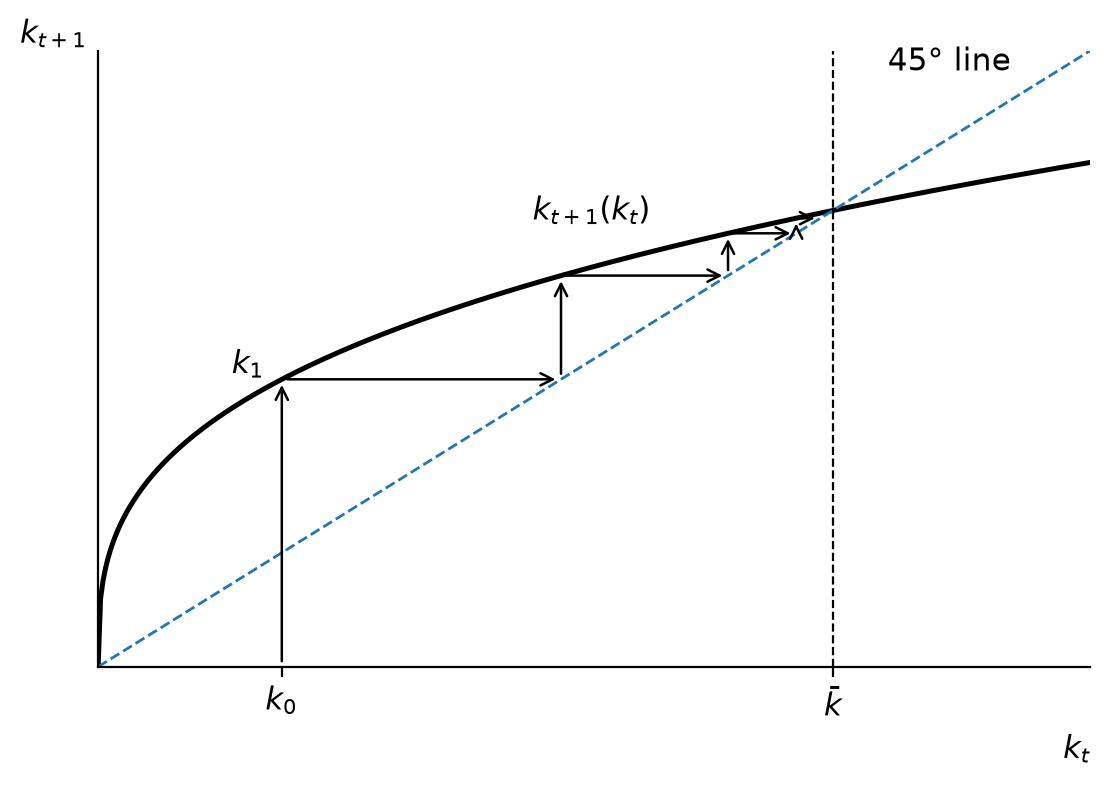

In [ ]:
YEARS = 30
epsilon, beta, Xi = 1 / 3, 0.96**YEARS, 1.01**YEARS
kbar = k_bar(epsilon, beta, Xi)

fig, ax = plt.subplots()
olg.draw_dynamics(ax, lambda k: k_next(k, epsilon, beta, Xi), kbar / 4, kbar)
style.save(fig, "OLGModelDynamics")

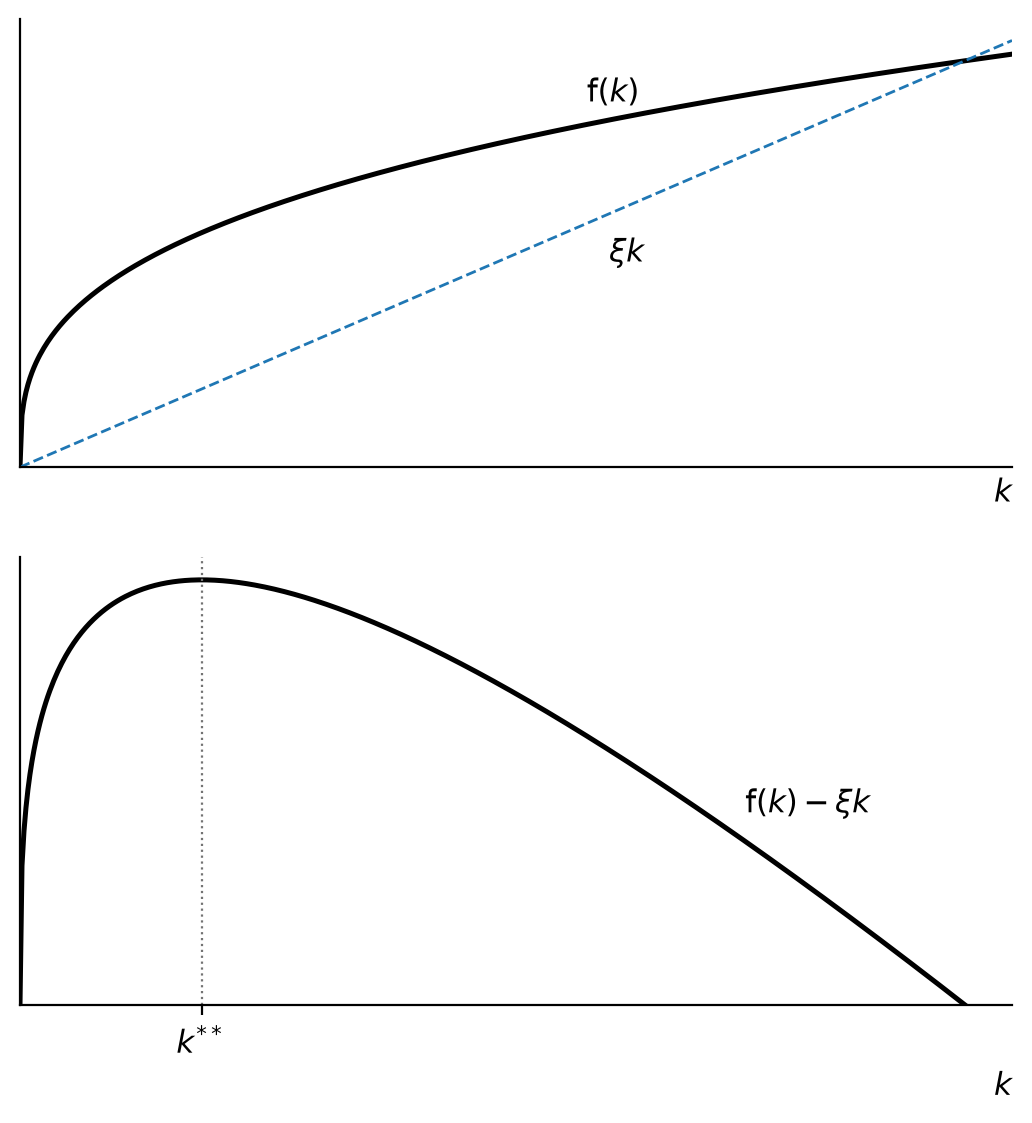

In [ ]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.4, 6.4))
olg.draw_output(top, bottom, epsilon, Xi - 1, k_golden(epsilon, Xi - 1))
style.save(fig, "fnkBoth")

## The chapter's results

In [ ]:
assert np.isclose(k_next(kbar, epsilon, beta, Xi), kbar)  # the steady state is a fixed point
k = kbar / 4
for _ in range(60):
    k = k_next(k, epsilon, beta, Xi)
assert np.isclose(k, kbar)  # and the economy converges to it
kgold = k_golden(epsilon, Xi - 1)
assert np.isclose(epsilon * kgold ** (epsilon - 1), Xi - 1)  # the golden rule: f'(k**) = xi
assert kbar < kgold  # at these values the economy is dynamically efficient
R = interest_factor(k_bar(epsilon, beta, 1.0), epsilon)
assert k_next_payg(k_bar(epsilon, beta, 1.0), epsilon, beta, 0.01, R) < k_bar(epsilon, beta, 1.0)  # Social Security lowers capital

## With sliders

Capital per worker: since $\log k_{t+1} = \log \mathcal{Q} + \varepsilon \log k_{t}$, each generation closes the fraction $1-\varepsilon$ of the gap, in logs, to the steady state, whatever the other parameters.

In [ ]:
olg.sliders_dynamics(k_next, k_bar, YEARS)

interactive(children=(FloatSlider(value=0.33, continuous_update=False, description='capital share ε', max=0.4,…

Output and the golden rule: the economy is dynamically inefficient when $\bar{k}$ exceeds $k^{**}$, which takes very patient consumers, a low capital share and fast population growth.

In [ ]:
olg.sliders_output(k_bar, k_golden, YEARS)

interactive(children=(FloatSlider(value=0.33, continuous_update=False, description='capital share ε', max=0.4,…

Introducing pay-as-you-go [Social Security](https://intertemporal-choice.github.io/content/consumption/socsecandkaccum): the young pay a share of their wage to the old, so they need to save less for retirement, and capital falls from $\bar{k}$ to a lower steady state $\bar{\bar{k}}$.

In [ ]:
olg.sliders_payg(k_next, k_next_payg, k_bar, interest_factor, wage, YEARS)

interactive(children=(FloatSlider(value=0.1, continuous_update=False, description='contribution, share of the …